In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.dpi'] = 110


# 1. Portfolio of two assets

For two assets with weights $\omega_1,\omega_2$ ($\omega_1+\omega_2=1$):

$$E(R_P)=\omega_1 E(R_1)+\omega_2 E(R_2)$$

$$\sigma_P^2=\omega_1^2\sigma_1^2+\omega_2^2\sigma_2^2+2\omega_1\omega_2\sigma_{1,2}$$

$$\sigma_P=\sqrt{\sigma_P^2}$$

# Worked example

Two securities $X$ and $Y$:

$$E(R_X)=5\%,\quad E(R_Y)=4\%,\quad \sigma_X^2=9,\quad \sigma_Y^2=6,\quad \sigma_{XY}=3$$


In [2]:
E_RX, E_RY = 0.05, 0.04
var_X, var_Y, cov_XY = 9, 6, 3   # given in the same (percentage^2-style) units as the notes

w_X = np.array([1.0, 0.8, 0.6, 0.4, 0.2, 0.0])
w_Y = 1 - w_X

E_Rp = w_X * E_RX + w_Y * E_RY
var_p = w_X**2 * var_X + w_Y**2 * var_Y + 2 * w_X * w_Y * cov_XY

table = pd.DataFrame({
    'w_X': w_X,
    'w_Y': w_Y,
    'E(Rp)': (E_Rp * 100).round(2).astype(str) + '%',
    'sigma_p^2': var_p.round(2).astype(str) + '%'
})
table


,w_X,w_Y,E(Rp),sigma_p^2
0,1.0,0.0,5.0%,9.0%
1,0.8,0.2,4.8%,6.96%
2,0.6,0.4,4.6%,5.64%
3,0.4,0.6,4.4%,5.04%
4,0.2,0.8,4.2%,5.16%
5,0.0,1.0,4.0%,6.0%


# 2. Portfolio of $N$ assets

For a vector of weights $\omega=\{\omega_1,\dots,\omega_N\}^T$ and mean-return vector
$\mu=\{\mu_1,\dots,\mu_N\}^T$ with $\mu_i=E(R_i)$:

$$E(R_P)=\omega^T\mu$$

$$\sigma_P=\sqrt{\omega^T\Sigma\,\omega}$$

where $\Sigma$ is the $N\times N$ covariance matrix of asset returns.

We compute the expected return and volatility for many random choices of $\omega$
(a Monte-Carlo cloud), and separately compute the **efficient frontier** — the set
of weights that minimise $\sigma_P$ for each target $E(R_P)$.


# 3. Data: `EuStockMarkets`

The R code uses the built-in `EuStockMarkets` dataset: daily closing prices
(1991–1998) of four major European stock indices — **DAX, SMI, CAC, FTSE**.

Python has no built-in copy of this dataset, so we pull the identical data
(same numbers R ships with) from the public Rdatasets mirror on GitHub.


In [3]:
url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/EuStockMarkets.csv"
eu = pd.read_csv(url, index_col=0)
eu.columns = ['DAX', 'SMI', 'CAC', 'FTSE']

Index_Value = eu.to_numpy()   # equivalent of R's as.matrix(EuStockMarkets)
print(Index_Value.shape)
eu.head()


(1860, 4)


,DAX,SMI,CAC,FTSE
rownames,,,,
1,1628.75,1678.1,1772.8,2443.6
2,1613.63,1688.5,1750.5,2460.2
3,1606.51,1678.6,1718.0,2448.2
4,1621.04,1684.1,1708.1,2470.4
5,1618.16,1686.6,1723.1,2484.7


In [4]:
# R: r <- diff(log(Index_Value)) * 100
r = np.diff(np.log(Index_Value), axis=0) * 100
r = pd.DataFrame(r, columns=eu.columns)
r.head()


,DAX,SMI,CAC,FTSE
0,-0.932655,0.617836,-1.265876,0.677029
1,-0.442218,-0.588045,-1.874064,-0.488959
2,0.900379,0.327118,-0.577918,0.902702
3,-0.177822,0.148337,0.874335,0.577185
4,-0.467671,-0.893342,-0.512016,-0.723016


# 4. Monte-Carlo cloud of random portfolios


**Note:** R and NumPy use different pseudo-random number generators, so even with a
matching seed the simulated cloud below will be statistically equivalent but not
numerically identical, point-for-point, to the original R run.


In [5]:
no_of_portf = 10000
rng = np.random.default_rng(1)
r_mat = r.to_numpy()

mu = np.full(no_of_portf, np.nan)
sigma = np.full(no_of_portf, np.nan)

for i in range(no_of_portf):
    w = rng.integers(1, 1001, size=4)        # sample(1:1000, 4, replace = TRUE)
    w = w / w.sum()                           # normalise so weights sum to 1
    rp = r_mat @ w                            # portfolio returns
    mu[i] = rp.mean()
    sigma[i] = rp.std(ddof=1)                 # R's sd() -> sample std. dev. (n-1)

mu[:5], sigma[:5]


(array([0.0546, 0.0467, 0.0529, 0.0647, 0.0703]),
 array([0.8179, 0.8357, 0.8751, 0.8137, 0.8948]))

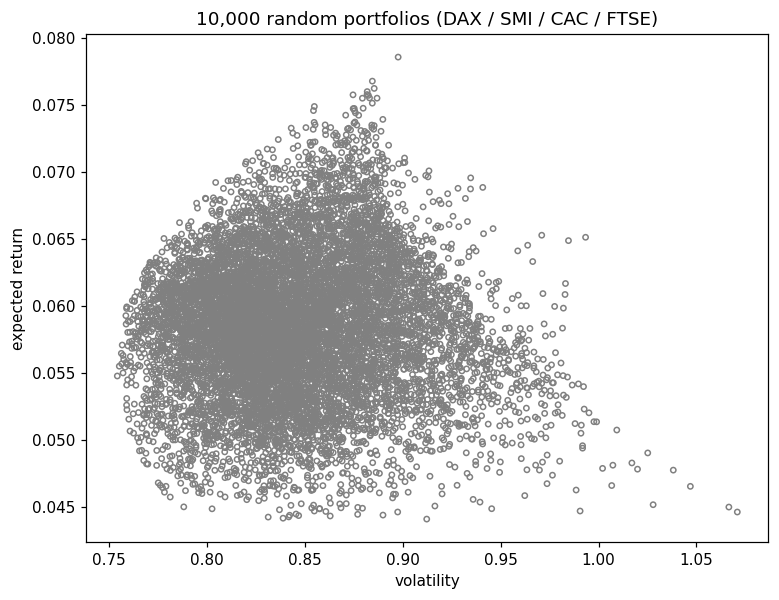

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(sigma, mu, facecolors='none', edgecolors='grey', s=12)
ax.set_xlabel('volatility')
ax.set_ylabel('expected return')
ax.set_title('10,000 random portfolios (DAX / SMI / CAC / FTSE)')
plt.show()


# 5. Efficient frontier


`portfolio.optim()` finds, for each target return `pm`, the **minimum-variance**
weights that achieve it — by default with **no short-selling** ($\omega_i \ge 0$).
The Python equivalent is a small quadratic program solved with `scipy.optimize.minimize`:

$$\min_{\omega}\ \omega^T\Sigma\omega \quad \text{s.t.} \quad \sum_i \omega_i = 1,\ \ \omega^T\mu = \text{target},\ \ \omega_i \ge 0$$


In [7]:
Sigma = r.cov().to_numpy()      # R: cov(r)
mu_assets = r.mean().to_numpy()
n_assets = len(mu_assets)

def min_vol_portfolio(target_return, mu_assets, Sigma, n_assets):
    # Minimum-variance portfolio for a given target return (no short-selling).
    def objective(w):
        return w @ Sigma @ w

    constraints = (
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
        {'type': 'eq', 'fun': lambda w: w @ mu_assets - target_return},
    )
    bounds = [(0, 1)] * n_assets          # w_i >= 0  (matches portfolio.optim default: shorts = FALSE)
    w0 = np.repeat(1 / n_assets, n_assets)

    res = minimize(objective, w0, method='SLSQP', bounds=bounds,
                   constraints=constraints, options={'maxiter': 500, 'ftol': 1e-12})
    if not res.success:
        return None
    w_opt = res.x
    vol = np.sqrt(w_opt @ Sigma @ w_opt)
    return vol, w_opt

er = np.arange(0.045, 0.075 + 1e-9, 0.001)
frontier = np.full((len(er), 2), np.nan)
frontier_weights = np.full((len(er), n_assets), np.nan)

for i, target in enumerate(er):
    result = min_vol_portfolio(target, mu_assets, Sigma, n_assets)
    if result is not None:
        vol, w_opt = result
        frontier[i] = [vol, target]
        frontier_weights[i] = w_opt

frontier[:5]


array([[0.7824, 0.045 ],
       [0.7775, 0.046 ],
       [0.773 , 0.047 ],
       [0.7689, 0.048 ],
       [0.7653, 0.049 ]])

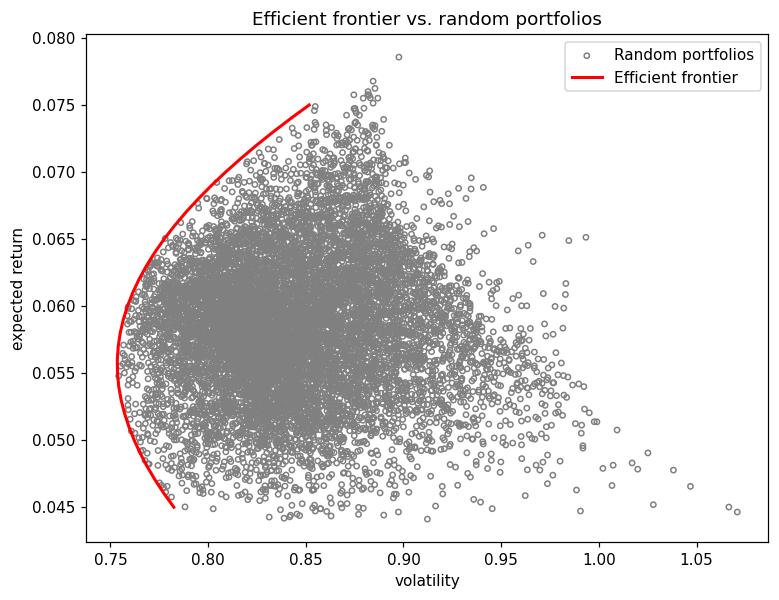

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(sigma, mu, facecolors='none', edgecolors='grey', s=12, label='Random portfolios')
ax.plot(frontier[:, 0], frontier[:, 1], color='red', lw=2, label='Efficient frontier')
ax.set_xlabel('volatility')
ax.set_ylabel('expected return')
ax.set_title('Efficient frontier vs. random portfolios')
ax.legend()
plt.show()


> *Portfolio **w1** and **w2** have the same expected return but different portfolio
> volatility. Which portfolio would you choose?*

- **w1** — the point **on the efficient frontier** with that return (minimum possible
  volatility for that return).
- **w2** — a portfolio from the **random Monte-Carlo cloud** with (approximately) the
  same return, but *not* optimised — i.e. an interior, inefficient point.


In [9]:
target_ret = 0.065

# w1: efficient portfolio with return closest to the target, taken from the frontier
idx_w1 = np.nanargmin(np.abs(frontier[:, 1] - target_ret))
vol_w1, ret_w1 = frontier[idx_w1]
weights_w1 = frontier_weights[idx_w1]

# w2: a random (non-optimal) portfolio from the simulated cloud with a similar return
idx_w2 = np.argmin(np.abs(mu - target_ret))
vol_w2, ret_w2 = sigma[idx_w2], mu[idx_w2]

print(f"w1 (efficient)   ->  return = {ret_w1:.4f}   volatility = {vol_w1:.4f}")
print(f"   weights (DAX, SMI, CAC, FTSE) = {np.round(weights_w1, 4)}")
print()
print(f"w2 (inefficient) ->  return = {ret_w2:.4f}   volatility = {vol_w2:.4f}")
print()
print(f"Volatility w2 is higher than w1 by {vol_w2 - vol_w1:.4f} "
      f"({(vol_w2/vol_w1 - 1)*100:.1f}% more risk) for essentially the same return.")


w1 (efficient)   ->  return = 0.0650   volatility = 0.7775
   weights (DAX, SMI, CAC, FTSE) = [0.     0.5649 0.     0.4351]

w2 (inefficient) ->  return = 0.0650   volatility = 0.8656

Volatility w2 is higher than w1 by 0.0881 (11.3% more risk) for essentially the same return.


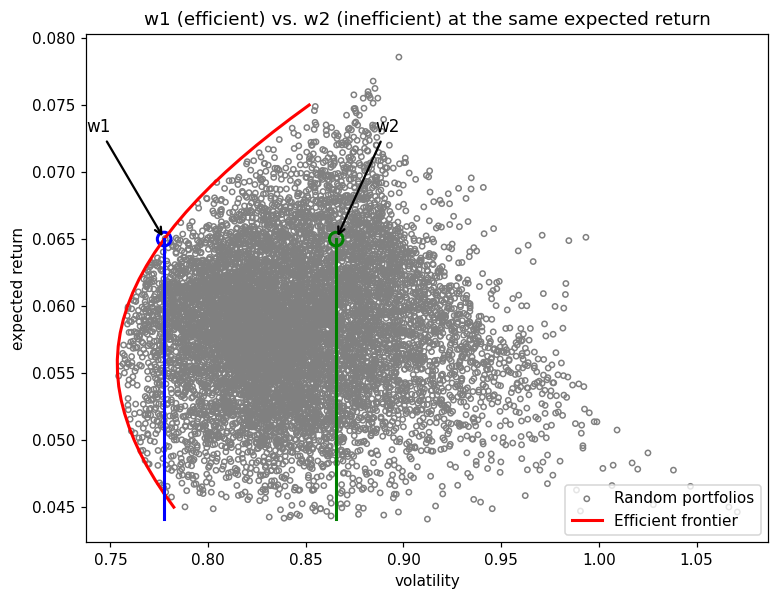

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(sigma, mu, facecolors='none', edgecolors='grey', s=12, label='Random portfolios')
ax.plot(frontier[:, 0], frontier[:, 1], color='red', lw=2, label='Efficient frontier')

ymin = mu.min()
ax.plot([vol_w1, vol_w1], [ymin, ret_w1], color='blue', lw=2)
ax.plot([vol_w2, vol_w2], [ymin, ret_w2], color='green', lw=2)

ax.annotate('w1', xy=(vol_w1, ret_w1), xytext=(vol_w1 - 0.04, ret_w1 + 0.008),
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5), fontsize=11)
ax.annotate('w2', xy=(vol_w2, ret_w2), xytext=(vol_w2 + 0.02, ret_w2 + 0.008),
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5), fontsize=11)

ax.scatter([vol_w1], [ret_w1], color='blue', facecolors='none', s=80, linewidths=2)
ax.scatter([vol_w2], [ret_w2], color='green', facecolors='none', s=80, linewidths=2)

ax.set_xlabel('volatility')
ax.set_ylabel('expected return')
ax.set_title('w1 (efficient) vs. w2 (inefficient) at the same expected return')
ax.legend(loc='lower right')
plt.show()


Both portfolios deliver essentially the same expected return (~6.5%), but **w1** lies
*on* the efficient frontier — it is the minimum-volatility portfolio that achieves that
return — while **w2** is an arbitrary combination of weights that reaches the same
return while carrying strictly more risk.

Under mean–variance portfolio theory, w2 is **dominated** by w1: a rational,
risk-averse investor is never compensated for the extra volatility in w2, since it
offers no additional expected return over w1. Every risk-averse investor's utility is
therefore at least as high under w1.

**General rule:** an investor should always hold a portfolio that lies on the
efficient frontier (the upper-left boundary of the feasible region) rather than in the
interior — interior points are always volatility-inefficient for their level of
expected return.
